# VizWiz answerability: data hand-off and baselines (Project 2.2)

**Group 4**, Multimodal Data Fusion, Adelaide University, Semester 2 2026. **Part owner:** Sanjai (data and baselines).

**What this notebook does**

1. Downloads VizWiz-VQA and the **labelled test annotations** (`VQA_test.json`), and builds the project splits: **train = official train, dev = official validation, test = official test** (8,000 pairs).
2. Builds the labels (`y = 1` means unanswerable) and the subgroup columns for the bias analysis: photo sharpness group, question frequency, answer type.
3. Extracts frozen **ViT-B/16**, **BERT-base** and **CLIP** features once and caches them on Drive, with `meta.csv` and `manifest.json` (the hand-off read by `src/data.py`).
4. Trains the baselines with the **shared training code in the repo** (`python -m src.train`): question-only, image-only, early fusion, late fusion and the CLIP reference, 3 seeds each, hard labels.
5. Adds two floor models (majority class, photo quality only), saved as `predictions.csv` in the format of `docs/data_contract.md`.
6. Runs the soft-label ablation (same code, `data.label: soft`).

**Where this fits:** cross-attention and gated fusion (Vish), evaluation and confidence intervals (Ruturaj) and subgroup results (Barath) all read the features and `runs/` folders written here.

**Run it:** Runtime > Change runtime type > **T4 GPU**, then Runtime > **Run all**. If the features are already cached on Drive (fingerprint `895f3ed603bb`), the photos are **not** downloaded again and the whole run takes about 15-20 minutes. A first run from scratch downloads about 20 GB of photos and takes about 45 minutes.

The crowd answers decide the label, so they are used **only** to build labels and for data analysis, never as model inputs.

## 1. Setup

All settings live in `CONFIG`. Model training settings come from `configs/default.yaml` in the repo, so baselines and fusion models are trained by exactly the same code.

In [1]:
import os, sys, re, json, time, shutil, subprocess, hashlib
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from tqdm import tqdm as _tqdm

tqdm = partial(_tqdm, ascii=True, mininterval=5)  # plain-text progress bars (no notebook widgets)
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

CONFIG = {
    # Code: the repo is cloned and every model is trained with its src/ code
    "repo_url": "https://github.com/vishnuvardhan0ffl/vizwiz-answerability-fusion.git",
    "repo_branch": "main",
    "repo_dir": "/content/vizwiz-answerability-fusion",
    "train_config": "configs/default.yaml",
    # Storage: features, runs, figures and results go to Drive; photos stay on local disk
    "use_drive": True,
    "drive_dir": "/content/drive/MyDrive/vizwiz_fusion",
    "local_out_dir": "/content/vizwiz_fusion",
    "data_dir": "/content/data/vizwiz",
    "local_features_dir": "/content/features_local",   # fast local copy of the features for training
    "download": True,
    # Labelled test annotations (Annotations.zip has no test labels)
    "test_annotations_url": "https://vizwiz.cs.colorado.edu/VizWiz_all_answers/VQA_test.json",
    "test_annotations_path": None,   # None = download from the URL above into data_dir
    # Quick check: rows per split (stratified). None = use everything
    "n_per_split": None,
    "sample_seed": 42,
    # Frozen encoders (same as the pilot and docs/data_contract.md)
    "image_model": "google/vit-base-patch16-224-in21k",
    "text_model": "bert-base-uncased",
    "use_clip": True,
    "clip_model": "openai/clip-vit-base-patch32",
    "image_size": 224,
    "image_token_grid": 7,           # 14x14 ViT patch tokens average-pooled to 7x7 = 49 region tokens
    "max_q_tokens": 40,
    "extract_batch_size": 64,
    "num_workers": 2,
    # Subgroups
    "rare_question_max_count": 1,    # rare question = seen at most this many times in train
    # Training (models and seeds come from the repo config)
    "trained_baselines": ["question_only", "image_only", "early", "clip_early", "late"],
    "soft_label_ablation": True,     # question_only and image_only again with data.label = soft
    "skip_finished_runs": True,      # do not retrain a model/seed that already has full dev + test predictions
    "train_overrides": {},           # keep empty for real runs (only used for quick tests)
    # Speed check
    "latency_runs": 50,
}

In [2]:
import torch

IN_COLAB = "google.colab" in sys.modules
if CONFIG["use_drive"] and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = Path(CONFIG["drive_dir"])
else:
    OUT = Path(CONFIG["local_out_dir"])

FEAT_DIR, FIG_DIR, RES_DIR, RUNS_DIR = OUT / "features", OUT / "figures", OUT / "results", OUT / "runs"
DATA = Path(CONFIG["data_dir"])
for d in (FEAT_DIR, FIG_DIR, RES_DIR, RUNS_DIR, DATA):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FEAS = {"device": DEVICE}
if DEVICE == "cuda":
    props = torch.cuda.get_device_properties(0)
    FEAS.update(gpu=props.name, gpu_vram_gb=round(props.total_memory / 1e9, 1))
    print(f"GPU: {props.name} ({FEAS['gpu_vram_gb']} GB)")
else:
    print("No GPU found. Use Runtime > Change runtime type > T4 GPU, then run again.")
print("Outputs ->", OUT)

Mounted at /content/drive
GPU: Tesla T4 (15.6 GB)
Outputs -> /content/drive/MyDrive/vizwiz_fusion


### Get the shared code from the repo

The repo is cloned (or updated) and all training goes through its `src/` code, so the code behind every result is the code on GitHub.

In [3]:
REPO = Path(CONFIG["repo_dir"])
if not (REPO / ".git").exists():
    subprocess.run(["git", "clone", "-q", "-b", CONFIG["repo_branch"], CONFIG["repo_url"], str(REPO)], check=True)
else:
    subprocess.run(["git", "-C", str(REPO), "pull", "-q"], check=False)
COMMIT = subprocess.run(["git", "-C", str(REPO), "rev-parse", "--short", "HEAD"],
                        capture_output=True, text=True).stdout.strip()
print(f"Repo at {REPO}, commit {COMMIT}")


def repo_python(*args):
    # Run `python <args>` from the repo root and show its output as it runs
    proc = subprocess.Popen([sys.executable, *args], cwd=REPO, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True)
    for line in proc.stdout:
        print(line, end="")
    if proc.wait() != 0:
        raise RuntimeError(f"python {' '.join(args)} failed (exit code {proc.returncode})")


repo_python("-m", "tests.test_smoke")

Repo at /content/vizwiz-answerability-fusion, commit 6e20a67
{'train': 300, 'dev': 80, 'test': 100} pairs | device: cuda
[question_only seed 0] epoch  1  dev AUPRC 0.9226  (0.9s)
[question_only seed 0] epoch  2  dev AUPRC 0.9906  (0.0s)
[image_only seed 0] epoch  1  dev AUPRC 0.9278  (0.0s)
[image_only seed 0] epoch  2  dev AUPRC 0.9883  (0.0s)
[early seed 0] epoch  1  dev AUPRC 1.0000  (0.1s)
[early seed 0] epoch  2  dev AUPRC 1.0000  (0.0s)
[cross_attention seed 0] epoch  1  dev AUPRC 1.0000  (0.5s)
[cross_attention seed 0] epoch  2  dev AUPRC 1.0000  (0.1s)
[gated seed 0] epoch  1  dev AUPRC 1.0000  (0.2s)
[gated seed 0] epoch  2  dev AUPRC 1.0000  (0.0s)
[late seed 0] question weight 0.30  dev AUPRC 1.0000
SMOKE TEST PASSED


## 2. Annotations and test labels

`Annotations.zip` holds train, validation and test questions, but the test file has no labels. The labelled test file is `VQA_test.json` from the VizWiz "all answers" release. The notebook checks that every test pair gets an `answerable` value; if not, it stops before training.

In [4]:
import requests

BASE_URL = "https://vizwiz.cs.colorado.edu/VizWiz_final"
IMAGE_ZIPS = {s: f"{BASE_URL}/images/{s}.zip" for s in ("train", "val", "test")}
DOWNLOAD_LOG = RES_DIR / "download_log.json"


def download(url, path, chunk=8 * 1024 * 1024):
    # Stream to disk with a progress bar; resume a partial file if the server allows it
    done = path.stat().st_size if path.exists() else 0
    headers = {"Range": f"bytes={done}-"} if done else {}
    with requests.get(url, stream=True, headers=headers, timeout=60) as r:
        if done and r.status_code != 206:
            done = 0
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0)) + done
        with open(path, "ab" if done else "wb") as f, tqdm(total=total, initial=done, unit="B",
                                                          unit_scale=True, desc=path.name) as bar:
            for block in r.iter_content(chunk):
                f.write(block)
                bar.update(len(block))


def download_and_extract(name, url, dest):
    marker = dest / f".{name}.done"
    if marker.exists():
        print(f"{name}: already done, skipping")
        return
    print(f"{name}: {shutil.disk_usage(dest).free / 1e9:.0f} GB free on local disk")
    zpath, t0 = dest / name, time.time()
    download(url, zpath)
    size_gb, t1 = zpath.stat().st_size / 1e9, time.time()
    subprocess.run(["unzip", "-q", "-o", str(zpath), "-d", str(dest)], check=True)
    zpath.unlink()
    marker.touch()
    log = json.loads(DOWNLOAD_LOG.read_text()) if DOWNLOAD_LOG.exists() else {}
    log[name] = {"size_gb": round(size_gb, 2), "download_min": round((t1 - t0) / 60, 1),
                 "unzip_min": round((time.time() - t1) / 60, 1)}
    DOWNLOAD_LOG.write_text(json.dumps(log, indent=2))
    print(f"{name}: {size_gb:.2f} GB, downloaded in {(t1 - t0) / 60:.1f} min")


if CONFIG["download"]:
    download_and_extract("Annotations.zip", f"{BASE_URL}/vqa_data/Annotations.zip", DATA)

TEST_LABELS = Path(CONFIG["test_annotations_path"] or DATA / "VQA_test.json")
if not TEST_LABELS.exists() and CONFIG["test_annotations_url"]:
    download(CONFIG["test_annotations_url"], TEST_LABELS)
print("Labelled test file:", TEST_LABELS if TEST_LABELS.exists() else "NOT FOUND")

Annotations.zip: 75 GB free on local disk


Annotations.zip: 100%|##########| 1.71M/1.71M [00:00<00:00, 12.5MB/s]


Annotations.zip: 0.00 GB, downloaded in 0.0 min


VQA_test.json: 100%|##########| 8.23M/8.23M [00:00<00:00, 38.6MB/s]

Labelled test file: /content/data/vizwiz/VQA_test.json


## 3. Labels, subgroups and splits

- **Label** `y = 1 - answerable` (1 = unanswerable). All main models use this hard label (`data.label: hard` in the repo config).
- **`unans_votes`**: how many of the 10 crowd answers say "unanswerable" or "unsuitable". `src/data.py` builds the soft label from it (vote share) for the ablation in section 7.
- **Question frequency**: how often the normalised question appears in **train**. A question is **rare** if it was seen at most once in train.

The feature fingerprint depends only on the image names and questions, in order. Adding the test labels does not change it, so the cached features are reused.

In [5]:
UNANS_VOTES = {"unanswerable", "unsuitable", "unsuitable image"}
SPLIT_NAMES = {"train": "train", "val": "dev", "test": "test"}
ORDER = {"train": 0, "dev": 1, "test": 2}


def find_one(root, filename):
    hits = sorted(p for p in Path(root).rglob(filename) if "__MACOSX" not in p.parts)
    if not hits:
        raise FileNotFoundError(f"{filename} not found under {root}. Did the Annotations.zip download finish?")
    return hits[0]


def load_split(json_path, official):
    with open(json_path) as f:
        records = json.load(f)
    if not isinstance(records, list):
        raise ValueError(f"{json_path} should hold a list of records, found {type(records).__name__}")
    rows = [{"image": r["image"],
             "question": str(r.get("question", "")).strip(),
             "answers": [str(a.get("answer", "")).strip().lower() for a in (r.get("answers") or [])],
             "answer_type": r.get("answer_type"),
             "answerable": r.get("answerable"),
             "official_split": official,
             "split": SPLIT_NAMES[official]} for r in records]
    print(f"{json_path.name}: {len(rows):,} records; fields: {sorted(records[0].keys())}")
    return pd.DataFrame(rows)


def split_index(df):
    return {s: np.where(df["split"].values == s)[0] for s in ORDER}


raw = pd.concat([load_split(find_one(DATA, f"{s}.json"), s) for s in ("train", "val", "test")], ignore_index=True)

# Test labels from VQA_test.json, matched by image name
if TEST_LABELS.exists():
    ext = load_split(TEST_LABELS, "test").drop_duplicates("image").set_index("image")
    is_test = (raw["split"] == "test").values
    n_match = int(raw.loc[is_test, "image"].isin(ext.index).sum())
    q_same = (raw.loc[is_test, "image"].map(ext["question"]) == raw.loc[is_test, "question"]).mean()
    print(f"Test pairs matched in {TEST_LABELS.name}: {n_match:,} of {int(is_test.sum()):,}; "
          f"same question text: {q_same:.1%}")
    raw.loc[is_test, "answerable"] = raw.loc[is_test, "image"].map(ext["answerable"]).values
    raw.loc[is_test, "answer_type"] = raw.loc[is_test, "image"].map(ext["answer_type"]).values
    ext_answers = ext["answers"].to_dict()
    raw["answers"] = [ext_answers.get(im, a) if t else a for im, a, t in zip(raw["image"], raw["answers"], is_test)]

raw["y"] = 1.0 - pd.to_numeric(raw["answerable"], errors="coerce")
n_test = int((raw.split == "test").sum())
n_test_lab = int(raw.loc[raw.split == "test", "y"].notna().sum())
HAS_TEST_LABELS = n_test > 0 and n_test_lab == n_test
print(f"Test pairs with an 'answerable' label: {n_test_lab:,} of {n_test:,}")
if not HAS_TEST_LABELS:
    print("WARNING: not every test pair has a label. Check VQA_test.json (it needs an 'answerable' field).\n"
          "Features and data analysis still run; training stops in section 6.")

raw["n_answers"] = raw["answers"].str.len()
raw["unans_votes"] = raw["answers"].apply(lambda a: sum(x in UNANS_VOTES for x in a))
raw["vote_share"] = np.where(raw["n_answers"] > 0, raw["unans_votes"] / raw["n_answers"].clip(lower=1), np.nan)


def norm_q(q):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]+", " ", q.lower())).strip()


raw["q_norm"] = raw["question"].map(norm_q)
train_counts = raw.loc[raw.split == "train", "q_norm"].value_counts()
raw["q_freq_train"] = raw["q_norm"].map(train_counts).fillna(0).astype(int)
raw["rare_question"] = raw["q_freq_train"] <= CONFIG["rare_question_max_count"]
raw["q_words"] = raw["question"].str.split().str.len()


def take(df, n, seed):
    # Optional small stratified sample for a quick check
    if n is None or n >= len(df):
        return df
    if df["y"].notna().all():
        return pd.concat([g.sample(max(1, round(n * len(g) / len(df))), random_state=seed)
                          for _, g in df.groupby("y")])
    return df.sample(n, random_state=seed)


def finalise(df):
    df = df.sort_values("split", key=lambda s: s.map(ORDER), kind="stable").reset_index(drop=True)
    df["row"] = np.arange(len(df))
    fp = hashlib.md5("|".join(df["image"] + "#" + df["question"]).encode()).hexdigest()[:12]
    return df, split_index(df), fp


meta = pd.concat([take(raw[raw.split == s], CONFIG["n_per_split"], CONFIG["sample_seed"]) for s in ORDER],
                 ignore_index=True)
meta, IDX, FINGERPRINT = finalise(meta)
display(meta.groupby("split", sort=False)["y"].agg(pairs="size", labelled="count", unanswerable_rate="mean").round(3))
print("Feature fingerprint:", FINGERPRINT)

train.json: 20,523 records; fields: ['answer_type', 'answerable', 'answers', 'image', 'question']
val.json: 4,319 records; fields: ['answer_type', 'answerable', 'answers', 'image', 'question']
test.json: 8,000 records; fields: ['image', 'question']
VQA_test.json: 8,000 records; fields: ['answer_type', 'answerable', 'answers', 'image', 'question']
Test pairs matched in VQA_test.json: 8,000 of 8,000; same question text: 100.0%
Test pairs with an 'answerable' label: 8,000 of 8,000


,pairs,labelled,unanswerable_rate
split,,,
train,20523,20523,0.270
dev,4319,4319,0.321
test,8000,8000,0.268


Feature fingerprint: 895f3ed603bb


### Photos: download only if something still has to be computed from them

Photos are needed only for feature extraction, the photo-quality measures and the latency test. If all three are already cached for this fingerprint, nothing is downloaded.

In [6]:
GROUPS = {"vit": ["img_cls", "img_tok", "img_ok"],
          "bert": ["txt_cls", "txt_mean", "txt_tok", "txt_mask"],
          "clip": ["clip_img", "clip_txt"]}
fpath = lambda name: FEAT_DIR / f"{name}_{FINGERPRINT}.npy"
have = lambda group: all(fpath(n).exists() for n in GROUPS[group])
QUAL_PATH = RES_DIR / f"image_quality_{FINGERPRINT}.csv"
LATENCY_PATH = RES_DIR / "encoder_latency.json"

# Latency from an earlier run of this notebook (older runs kept it inside baselines_summary.json)
OLD_SUMMARY = RES_DIR / "baselines_summary.json"
if not LATENCY_PATH.exists() and OLD_SUMMARY.exists():
    old_lat = json.loads(OLD_SUMMARY.read_text()).get("feasibility", {}).get("encoder_latency")
    if old_lat:
        LATENCY_PATH.write_text(json.dumps(old_lat, indent=2))

needed = {"features": not (have("vit") and have("bert") and (have("clip") or not CONFIG["use_clip"])),
          "photo quality": not QUAL_PATH.exists(), "latency": not LATENCY_PATH.exists()}
NEED_IMAGES = any(needed.values())
print("Still to compute from photos:", [k for k, v in needed.items() if v] or "nothing (photos not needed)")

if NEED_IMAGES:
    if CONFIG["download"]:
        for s, url in IMAGE_ZIPS.items():
            download_and_extract(f"{s}.zip", url, DATA)
    img_index = {}
    for dirpath, _, files in os.walk(DATA, followlinks=True):
        for f in files:
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                img_index[f] = os.path.join(dirpath, f)
    meta["path"] = meta["image"].map(img_index)
    missing = int(meta["path"].isna().sum())
    print(f"Photos found: {len(img_index):,}; pairs without a photo: {missing}")
    if missing == len(meta):
        raise RuntimeError(f"No photos found under {DATA}. Check that the image zips finished unzipping.")
    if missing:
        meta, IDX, FINGERPRINT = finalise(meta.dropna(subset=["path"]))
        print("Pairs without a photo were dropped; new fingerprint:", FINGERPRINT)
PATHS = meta["path"].tolist() if "path" in meta else None
QUESTIONS = meta["question"].tolist()

Still to compute from photos: ['features', 'photo quality', 'latency']
train.zip: 75 GB free on local disk


train.zip: 100%|##########| 11.3G/11.3G [03:20<00:00, 56.3MB/s]


train.zip: 11.30 GB, downloaded in 3.3 min
val.zip: 64 GB free on local disk


val.zip: 100%|##########| 3.49G/3.49G [01:05<00:00, 53.5MB/s]


val.zip: 3.49 GB, downloaded in 1.1 min
test.zip: 60 GB free on local disk


test.zip: 100%|##########| 3.98G/3.98G [01:04<00:00, 61.6MB/s]


test.zip: 3.98 GB, downloaded in 1.1 min
Photos found: 39,704; pairs without a photo: 0


## 4. Data characterisation

Photo sharpness is the variance of the Laplacian, a standard focus measure (Pech-Pacheco et al. 2000), computed for **every** photo (not a sample), so each pair can be put in a sharpness group: **blurry / medium / sharp**, cut at the train tertiles. Sharpness is compared between answerable and unanswerable photos with a two-sided Mann-Whitney U test (Mann & Whitney 1947). The result is cached, so this only runs once. Choices (sharpness cut points, rare-question counts) use train only; test is only described here, never used for tuning.

In [7]:
from multiprocessing import Pool
from PIL import Image, ImageOps
from scipy.stats import mannwhitneyu


def image_quality(path, size=256):
    try:
        with Image.open(path) as im:
            w, h = im.size
            im.draft("L", (size, size))  # fast reduced-size JPEG decode
            g = np.asarray(ImageOps.exif_transpose(im).convert("L").resize((size, size)), dtype=np.float32)
        lap = g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:] - 4 * g[1:-1, 1:-1]
        return w, h, os.path.getsize(path) / 1024, float(lap.var()), float(g.mean()), 1
    except Exception:
        return np.nan, np.nan, np.nan, np.nan, np.nan, 0


QUAL_COLS = ["width", "height", "file_kb", "sharpness", "brightness", "readable"]
QUAL_PATH = RES_DIR / f"image_quality_{FINGERPRINT}.csv"
if QUAL_PATH.exists():
    qual = pd.read_csv(QUAL_PATH)
    print("Loaded cached photo quality")
else:
    with Pool(max(1, os.cpu_count() or 1)) as pool:
        qual = pd.DataFrame(list(tqdm(pool.imap(image_quality, meta["path"], chunksize=64),
                                      total=len(meta), desc="photo quality")), columns=QUAL_COLS)
    qual.insert(0, "image", meta["image"].values)
    qual.to_csv(QUAL_PATH, index=False)
assert (qual["image"].values == meta["image"].values).all()
for c in QUAL_COLS:
    meta[c] = qual[c].values
meta["megapixels"] = meta["width"] * meta["height"] / 1e6

# Sharpness groups cut at the train tertiles
tr_sharp = meta.loc[IDX["train"], "sharpness"].dropna()
cuts = np.quantile(tr_sharp, [1 / 3, 2 / 3])
meta["sharp_bin"] = pd.cut(meta["sharpness"].fillna(tr_sharp.median()), [-np.inf, cuts[0], cuts[1], np.inf],
                           labels=["blurry", "medium", "sharp"]).astype(str)
print(f"Unreadable photos: {int((meta['readable'] == 0).sum())}; sharpness cuts at {cuts.round(1)}")

photo quality: 100%|##########| 32842/32842 [04:45<00:00, 114.84it/s]


Unreadable photos: 0; sharpness cuts at [153.5 485.1]


In [8]:
LAB = {0: "answerable", 1: "unanswerable"}
tr = meta.loc[IDX["train"]]
lab = meta[meta["y"].notna()]
top_q = (tr.groupby("q_norm")["y"].agg(count="size", unanswerable_rate="mean")
         .sort_values("count", ascending=False).head(10).round(3))
mw = mannwhitneyu(tr.loc[tr.y == 0, "sharpness"].dropna(), tr.loc[tr.y == 1, "sharpness"].dropna())

STATS = {
    "n_pairs_by_split": {s: int(len(IDX[s])) for s in IDX},
    "unanswerable_rate_by_split": lab.groupby("split")["y"].mean().round(3).to_dict(),
    "ambiguous_answerable_share_train": round(float(((tr.y == 0) & (tr.unans_votes >= 3)).mean()), 3),
    "ambiguous_share_of_answerable_train": round(float((tr.loc[tr.y == 0, "unans_votes"] >= 3).mean()), 3),
    "repeated_question_share_train": round(float((tr.q_freq_train >= 2).mean()), 3),
    # Same definition as the pilot and proposal (exact lower-case text, train + dev): 57.6% in the pilot
    "duplicate_questions_share_pilot_def": round(float(
        meta.loc[np.r_[IDX["train"], IDX["dev"]], "question"].str.lower().duplicated(keep=False).mean()), 3),
    "rare_question_share_by_split": meta.groupby("split")["rare_question"].mean().round(3).to_dict(),
    "unseen_question_share_test": round(float((meta.loc[IDX["test"], "q_freq_train"] == 0).mean()), 3),
    "question_words_median": float(meta["q_words"].median()),
    "sharpness_median_by_label_train": {LAB[int(k)]: v for k, v in tr.groupby("y")["sharpness"].median().round(1).items()},
    "sharpness_mannwhitney_p_train": float(mw.pvalue),
    "unanswerable_rate_by_sharp_bin_train": tr.groupby("sharp_bin")["y"].mean().round(3).to_dict(),
    "unreadable_photos": int((meta["readable"] == 0).sum()),
    "top_questions_train": top_q.reset_index().to_dict(orient="records"),
}

# The proposal's findings table, recomputed on the full data
r = STATS["unanswerable_rate_by_split"]
findings = pd.DataFrame([
    ["Unanswerable share by split", ", ".join(f"{k} {v:.1%}" for k, v in r.items()),
     "Weighted loss (pos_weight) and dev-tuned threshold"],
    ["Answerable pairs with >= 3/10 'unanswerable' votes (train)", f"{STATS['ambiguous_answerable_share_train']:.1%} of pairs",
     "Hard labels for main models; soft-label ablation"],
    ["Train pairs whose question repeats in train", f"{STATS['repeated_question_share_train']:.1%}",
     "Question-only baseline; rare-question subset"],
    ["Test questions rare in train (<= 1 time)", f"{STATS['rare_question_share_by_split'].get('test', float('nan')):.1%}",
     "Report rare vs common results"],
    ["Sharpness, answerable vs unanswerable (train median)",
     f"{STATS['sharpness_median_by_label_train']} (p = {STATS['sharpness_mannwhitney_p_train']:.1e})",
     "Sharpness-stratified evaluation; photo-quality baseline"],
], columns=["Finding", "Value", "Mitigation"])
display(findings)
print("\nMost frequent train questions:")
display(top_q)

,Finding,Value,Mitigation
0,Unanswerable share by split,"dev 32.1%, test 26.8%, train 27.0%",Weighted loss (pos_weight) and dev-tuned thres...
1,Answerable pairs with >= 3/10 'unanswerable' v...,12.2% of pairs,Hard labels for main models; soft-label ablation
2,Train pairs whose question repeats in train,59.4%,Question-only baseline; rare-question subset
3,Test questions rare in train (<= 1 time),46.2%,Report rare vs common results
4,"Sharpness, answerable vs unanswerable (train m...","{'answerable': 347.5, 'unanswerable': 155.8} (...",Sharpness-stratified evaluation; photo-quality...



Most frequent train questions:


,count,unanswerable_rate
q_norm,,
what is this,3078,0.115
what color is this,425,0.019
what is it,298,0.094
what is this item,270,0.130
what does this say,226,0.341
what color is this shirt,209,0.062
what s this,182,0.154
what is that,170,0.076
what is in this box,167,0.102


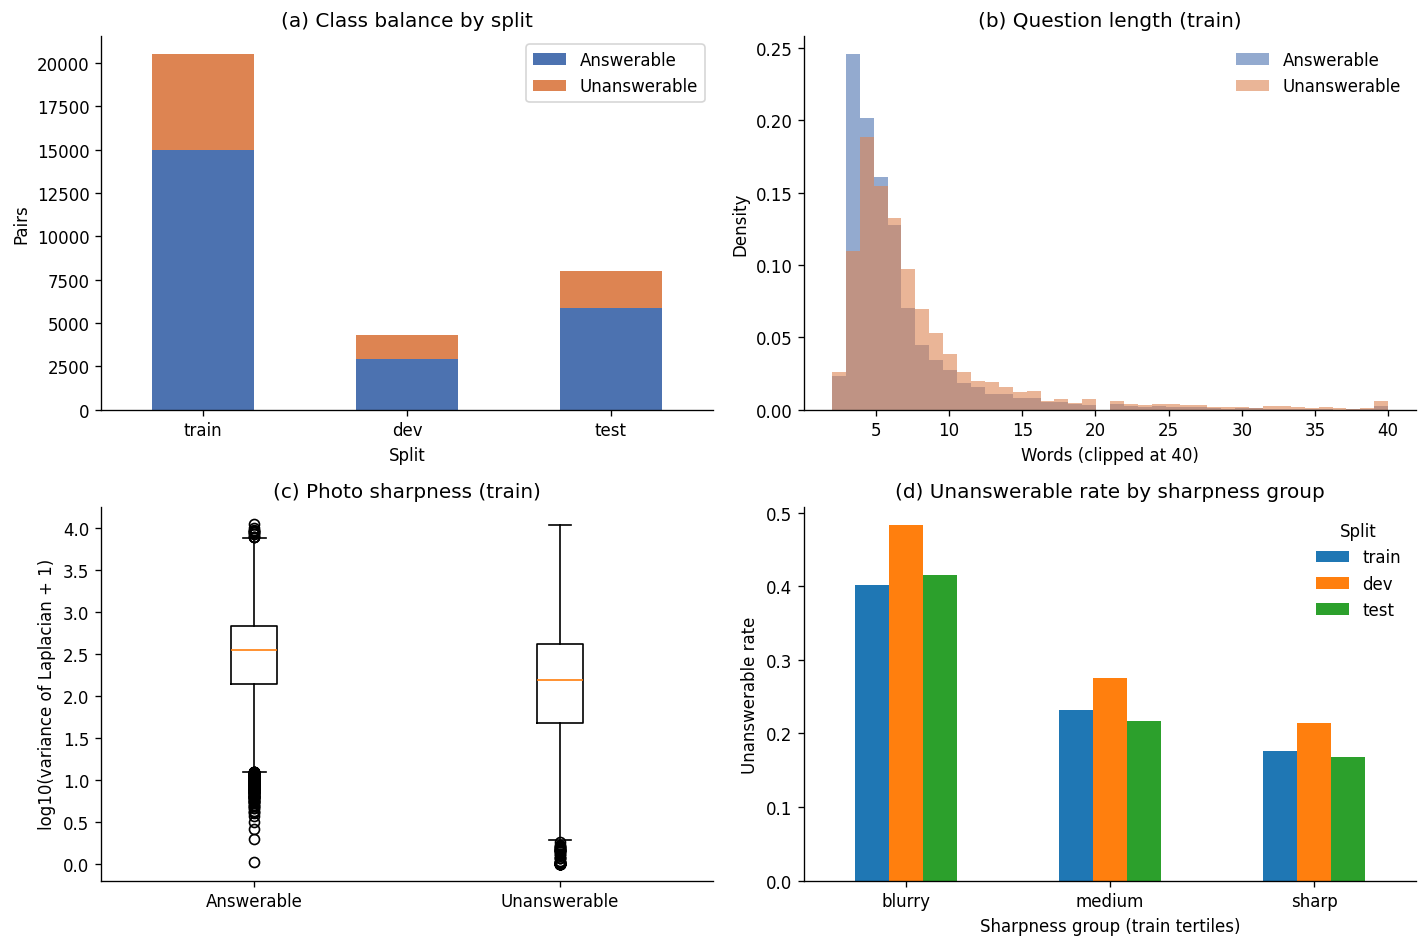

In [9]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
LABELS = {0: "Answerable", 1: "Unanswerable"}
COLOURS = {0: "#4C72B0", 1: "#DD8452"}
splits = [s for s in ("train", "dev", "test") if len(IDX[s])]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
ax = axes[0, 0]
counts = lab.groupby(["split", "y"]).size().unstack().reindex([s for s in splits if s in lab.split.values])
counts.columns = [LABELS[int(c)] for c in counts.columns]
counts.plot(kind="bar", stacked=True, ax=ax, color=[COLOURS[0], COLOURS[1]], rot=0)
ax.set(title="(a) Class balance by split", xlabel="Split", ylabel="Pairs")

ax = axes[0, 1]
for y in (0, 1):
    ax.hist(tr.loc[tr.y == y, "q_words"].clip(upper=40), bins=40, alpha=0.6, density=True,
            label=LABELS[y], color=COLOURS[y])
ax.set(title="(b) Question length (train)", xlabel="Words (clipped at 40)", ylabel="Density")
ax.legend(frameon=False)

ax = axes[1, 0]
ax.boxplot([np.log10(tr.loc[tr.y == y, "sharpness"].dropna() + 1) for y in (0, 1)])
ax.set_xticks([1, 2], [LABELS[0], LABELS[1]])
ax.set(title="(c) Photo sharpness (train)", ylabel="log10(variance of Laplacian + 1)")

ax = axes[1, 1]
rate = lab.groupby(["sharp_bin", "split"])["y"].mean().unstack().reindex(["blurry", "medium", "sharp"])
rate = rate[[s for s in splits if s in rate.columns]]
rate.plot(kind="bar", ax=ax, rot=0)
ax.set(title="(d) Unanswerable rate by sharpness group", xlabel="Sharpness group (train tertiles)",
       ylabel="Unanswerable rate")
ax.legend(title="Split", frameon=False)

fig.tight_layout()
fig.savefig(FIG_DIR / "data_characterisation.png", bbox_inches="tight")
plt.show()

## 5. Frozen feature extraction

Each encoder runs once and its output is saved to Drive straight away, so a Colab disconnect only loses the encoder that was running. If the features are cached, this section only loads them. Freezing pretrained encoders suits about 20,000 training pairs, which is too few to train them from scratch.

| Name | Shape | What it is |
|---|---|---|
| `img_cls` | N x 768 | ViT-B/16 [CLS] vector (Dosovitskiy et al. 2021) |
| `img_tok` | N x 49 x 768 | 14x14 patch tokens pooled to 7x7 region tokens (for cross-attention) |
| `img_ok` | N | 1 = photo read fine, 0 = unreadable (zero input) |
| `txt_cls`, `txt_mean` | N x 768 | BERT-base [CLS] and mask-aware mean (Devlin et al. 2019) |
| `txt_tok`, `txt_mask` | N x 40 x 768, N x 40 | BERT word tokens and padding mask (for cross-attention) |
| `clip_img`, `clip_txt` | N x 512 | CLIP ViT-B/32 image and text embeddings (Radford et al. 2021), reference only |

Photos get EXIF rotation and an **uncropped** 224x224 resize, because questions often ask about text near the edge of the frame. Row i of every array is row i of `meta.csv`.

In [10]:
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from transformers import AutoImageProcessor, AutoModel, AutoTokenizer

DESCRIPTIONS = {
    "img_cls": "ViT-B/16 [CLS] vector", "img_tok": "ViT-B/16 7x7 region tokens", "img_ok": "1 = photo readable",
    "txt_cls": "BERT [CLS] vector", "txt_mean": "BERT mask-aware mean", "txt_tok": "BERT word tokens",
    "txt_mask": "BERT padding mask (1 = real token)", "clip_img": "CLIP image embedding",
    "clip_txt": "CLIP text embedding"}
EXTRACTION_LOG = FEAT_DIR / f"extraction_log_{FINGERPRINT}.json"
if EXTRACTION_LOG.exists():
    FEAS.update(json.loads(EXTRACTION_LOG.read_text()))


def autocast():
    return torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=(DEVICE == "cuda"))


def reset_peak():
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()


def peak_gb():
    return round(torch.cuda.max_memory_allocated() / 1e9, 2) if DEVICE == "cuda" else None


def log_step(key, value):
    FEAS[key] = value
    keep = {k: FEAS[k] for k in FEAS if k.endswith("_extraction")}
    EXTRACTION_LOG.write_text(json.dumps(keep, indent=2))


def as_embedding(out):
    # transformers 4.x returns a tensor here, 5.x returns an output object
    return out if torch.is_tensor(out) else out.pooler_output


class PhotoDataset(Dataset):
    def __init__(self, paths, size, mean, std):
        self.paths, self.size = list(paths), size
        self.mean = torch.tensor(mean, dtype=torch.float32).view(3, 1, 1)
        self.std = torch.tensor(std, dtype=torch.float32).view(3, 1, 1)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        try:
            with Image.open(self.paths[i]) as im:
                im.draft("RGB", (self.size, self.size))
                im = ImageOps.exif_transpose(im).convert("RGB").resize((self.size, self.size),
                                                                     Image.Resampling.BICUBIC)
            x = torch.from_numpy(np.asarray(im, dtype=np.float32) / 255.0).permute(2, 0, 1)
            return (x - self.mean) / self.std, 1
        except Exception:
            return torch.zeros(3, self.size, self.size), 0


def photo_loader(paths, mean, std):
    return DataLoader(PhotoDataset(paths, CONFIG["image_size"], mean, std), batch_size=CONFIG["extract_batch_size"],
                      num_workers=CONFIG["num_workers"], pin_memory=(DEVICE == "cuda"))


@torch.no_grad()
def extract_vit(paths):
    proc = AutoImageProcessor.from_pretrained(CONFIG["image_model"])
    model = AutoModel.from_pretrained(CONFIG["image_model"]).to(DEVICE).eval()
    n, g, d = len(paths), CONFIG["image_token_grid"], model.config.hidden_size
    cls, tok, ok = np.empty((n, d), np.float16), np.empty((n, g * g, d), np.float16), np.empty(n, np.uint8)
    reset_peak()
    t0, i = time.time(), 0
    for x, flag in tqdm(photo_loader(paths, proc.image_mean, proc.image_std), desc="ViT features"):
        x = x.to(DEVICE, non_blocking=True)
        with autocast():
            h = model(pixel_values=x).last_hidden_state
        b, side = len(x), int(round((h.shape[1] - 1) ** 0.5))
        grid = h[:, 1:].float().reshape(b, side, side, d).permute(0, 3, 1, 2)
        regions = F.adaptive_avg_pool2d(grid, g).flatten(2).transpose(1, 2)
        cls[i:i + b], tok[i:i + b], ok[i:i + b] = h[:, 0].float().cpu().numpy(), regions.cpu().numpy(), flag.numpy()
        i += b
    secs = time.time() - t0
    log_step("image_extraction", {"n": n, "minutes": round(secs / 60, 1), "images_per_sec": round(n / secs, 1),
                                  "peak_vram_gb": peak_gb(), "unreadable_images": int((ok == 0).sum())})
    return {"img_cls": cls, "img_tok": tok, "img_ok": ok}


@torch.no_grad()
def extract_bert(questions):
    tokenizer = AutoTokenizer.from_pretrained(CONFIG["text_model"])
    model = AutoModel.from_pretrained(CONFIG["text_model"]).to(DEVICE).eval()
    n, L, d, bs = len(questions), CONFIG["max_q_tokens"], model.config.hidden_size, 2 * CONFIG["extract_batch_size"]
    cls, mean = np.empty((n, d), np.float16), np.empty((n, d), np.float16)
    tok, mask = np.empty((n, L, d), np.float16), np.empty((n, L), np.uint8)
    full_len = np.array([len(t) for t in tokenizer(questions)["input_ids"]])
    reset_peak()
    t0 = time.time()
    for i in tqdm(range(0, n, bs), desc="BERT features"):
        enc = tokenizer(questions[i:i + bs], padding="max_length", truncation=True, max_length=L,
                        return_tensors="pt").to(DEVICE)
        with autocast():
            h = model(**enc).last_hidden_state
        h, m = h.float(), enc["attention_mask"].unsqueeze(-1).float()
        cls[i:i + bs] = h[:, 0].cpu().numpy()
        mean[i:i + bs] = ((h * m).sum(1) / m.sum(1).clamp(min=1)).cpu().numpy()
        tok[i:i + bs], mask[i:i + bs] = h.cpu().numpy(), enc["attention_mask"].cpu().numpy()
    log_step("text_extraction", {"n": n, "minutes": round((time.time() - t0) / 60, 1), "peak_vram_gb": peak_gb(),
                                 "truncated_share": round(float((full_len > L).mean()), 4)})
    return {"txt_cls": cls, "txt_mean": mean, "txt_tok": tok, "txt_mask": mask}


@torch.no_grad()
def extract_clip(paths, questions):
    from transformers import CLIPModel
    proc = AutoImageProcessor.from_pretrained(CONFIG["clip_model"])
    tokenizer = AutoTokenizer.from_pretrained(CONFIG["clip_model"])
    model = CLIPModel.from_pretrained(CONFIG["clip_model"]).to(DEVICE).eval()
    img, txt = [], []
    reset_peak()
    t0 = time.time()
    for x, _ in tqdm(photo_loader(paths, proc.image_mean, proc.image_std), desc="CLIP image"):
        with autocast():
            img.append(as_embedding(model.get_image_features(pixel_values=x.to(DEVICE))).float().cpu().numpy())
    bs = 2 * CONFIG["extract_batch_size"]
    for i in tqdm(range(0, len(questions), bs), desc="CLIP text"):
        enc = tokenizer(questions[i:i + bs], padding=True, truncation=True, max_length=77,
                        return_tensors="pt").to(DEVICE)
        with autocast():
            txt.append(as_embedding(model.get_text_features(**enc)).float().cpu().numpy())
    log_step("clip_extraction", {"n": len(paths), "minutes": round((time.time() - t0) / 60, 1),
                                 "peak_vram_gb": peak_gb()})
    return {"clip_img": np.concatenate(img).astype(np.float16), "clip_txt": np.concatenate(txt).astype(np.float16)}


def run_group(group, fn, *args):
    if have(group):
        print(f"{group}: cached")
        return
    arrays = fn(*args)
    for name, arr in arrays.items():
        np.save(fpath(name), arr)
    del arrays
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    print(f"{group}: saved")


run_group("vit", extract_vit, PATHS)
run_group("bert", extract_bert, QUESTIONS)
if CONFIG["use_clip"]:
    run_group("clip", extract_clip, PATHS, QUESTIONS)

ViT features: 100%|##########| 514/514 [06:01<00:00,  1.42it/s]


vit: saved


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
BERT features: 100%|##########| 257/257 [00:23<00:00, 10.73it/s]


bert: saved


CLIP text: 100%|##########| 257/257 [00:13<00:00, 18.70it/s]


clip: saved


### Hand-off files: `meta.csv` and `manifest.json`

`meta.csv` has one row per pair, in feature order. It has the columns required by `docs/data_contract.md` (`pair_id`, `question`, `official_split`, `y`, `unans_votes`) plus the subgroup columns for the bias part. It contains questions, so it stays on Drive and is **never committed** to GitHub.

In [11]:
meta["img_ok"] = np.load(fpath("img_ok"))
meta["pair_id"] = meta["image"]
assert meta["pair_id"].is_unique, "pair_id (image file name) must be unique"
META_COLS = ["pair_id", "question", "official_split", "y", "unans_votes", "row", "split", "vote_share",
             "answer_type", "q_norm", "q_words", "q_freq_train", "rare_question", "width", "height", "megapixels",
             "file_kb", "sharpness", "brightness", "sharp_bin", "readable", "img_ok"]
meta[META_COLS].to_csv(FEAT_DIR / "meta.csv", index=False)

feature_names = GROUPS["vit"] + GROUPS["bert"] + (GROUPS["clip"] if CONFIG["use_clip"] else [])
manifest = {
    "fingerprint": FINGERPRINT, "n_rows": int(len(meta)),
    "rows_by_split": {s: int(len(IDX[s])) for s in IDX}, "has_test_labels": HAS_TEST_LABELS,
    "test_labels_file": TEST_LABELS.name, "created": time.strftime("%Y-%m-%d %H:%M"),
    "encoders": {k: CONFIG[k] for k in ("image_model", "text_model", "clip_model", "image_size",
                                        "image_token_grid", "max_q_tokens")},
    "meta": "meta.csv", "features": {},
}
for n in feature_names:
    a = np.load(fpath(n), mmap_mode="r")
    manifest["features"][n] = {"file": fpath(n).name, "shape": list(a.shape), "dtype": str(a.dtype),
                               "description": DESCRIPTIONS[n]}
(FEAT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))
FEAS["features_on_disk_gb"] = round(sum(fpath(n).stat().st_size for n in feature_names) / 1e9, 2)
print(json.dumps({k: v for k, v in FEAS.items() if k.endswith("extraction") or k == "features_on_disk_gb"}, indent=2))

{
  "image_extraction": {
    "n": 32842,
    "minutes": 6.0,
    "images_per_sec": 90.8,
    "peak_vram_gb": 0.94,
    "unreadable_images": 0
  },
  "text_extraction": {
    "n": 32842,
    "minutes": 0.4,
    "peak_vram_gb": 0.78,
    "truncated_share": 0.0091
  },
  "clip_extraction": {
    "n": 32842,
    "minutes": 5.9,
    "peak_vram_gb": 0.95
  },
  "features_on_disk_gb": 4.71
}


### Encoder latency (one query, batch size 1)

The proposal sets a limit of 100 ms per query on a T4. The frozen encoders are almost all of that cost, so the encoder time is measured here: read and resize one photo, run ViT-B/16, tokenise and run BERT-base. The evaluation part adds the head time on top. The result is cached in `results/encoder_latency.json`.

In [12]:
@torch.no_grad()
def encoder_latency(n_runs):
    proc = AutoImageProcessor.from_pretrained(CONFIG["image_model"])
    vit = AutoModel.from_pretrained(CONFIG["image_model"]).to(DEVICE).eval()
    tokenizer = AutoTokenizer.from_pretrained(CONFIG["text_model"])
    bert = AutoModel.from_pretrained(CONFIG["text_model"]).to(DEVICE).eval()
    ds = PhotoDataset(PATHS, CONFIG["image_size"], proc.image_mean, proc.image_std)
    times = []
    for k in range(n_runs + 5):
        i = k % len(ds)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        x, _ = ds[i]
        enc = tokenizer([QUESTIONS[i]], truncation=True, max_length=CONFIG["max_q_tokens"],
                        return_tensors="pt").to(DEVICE)
        with autocast():
            vit(pixel_values=x.unsqueeze(0).to(DEVICE))
            bert(**enc)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        if k >= 5:  # first 5 runs are warm-up
            times.append((time.perf_counter() - t0) * 1000)
    del vit, bert
    return {"median_ms": round(float(np.median(times)), 1), "p95_ms": round(float(np.percentile(times, 95)), 1),
            "runs": n_runs, "device": FEAS.get("gpu", DEVICE)}


if LATENCY_PATH.exists():
    FEAS["encoder_latency"] = json.loads(LATENCY_PATH.read_text())
    print("Loaded cached latency")
else:
    FEAS["encoder_latency"] = encoder_latency(CONFIG["latency_runs"])
    LATENCY_PATH.write_text(json.dumps(FEAS["encoder_latency"], indent=2))
print(FEAS["encoder_latency"], "(target: <= 100 ms per query on a T4, including the fusion head)")

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'median_ms': 37.3, 'p95_ms': 58.2, 'runs': 50, 'device': 'Tesla T4'} (target: <= 100 ms per query on a T4, including the fusion head)


## 6. Train the baselines with the shared code

Every trained model goes through `python -m src.train` from the repo, with the settings in `configs/default.yaml` (hard labels, BCE with `pos_weight`, AdamW, early stopping on dev AUPRC, seeds 0, 1, 2). Outputs follow `docs/data_contract.md`: `runs/<model>/seed<k>/` with `model.pt`, `history.csv`, `predictions.csv` and `summary.json`.

| Model | Input | Why |
|---|---|---|
| `question_only` | BERT mean vector | Question priors |
| `image_only` | ViT [CLS] vector | Photo content |
| `early` | both vectors joined, then MLP | Simplest fusion |
| `late` | weighted average of the two single-modality probabilities, weight tuned on dev | Fusion of decisions |
| `clip_early` | CLIP text + image vectors joined, then MLP | Reference encoder trained to match images and text (Radford et al. 2021) |

The features are first copied from Drive to the Colab disk, because every training run reads all of them and the local disk is much faster.

In [13]:
import yaml

if not HAS_TEST_LABELS:
    raise RuntimeError("Some test pairs have no label, so training would give no test scores. "
                       "Fix the test labels in section 2 first.")

sys.path.insert(0, str(REPO))
import importlib
import src.models, src.train
importlib.reload(src.models)
importlib.reload(src.train)
TRAINABLE = list(src.train.TRAINABLE)
MANIFEST_LOADER = "manifest" in (REPO / "src" / "data.py").read_text()
print("Trainable models in the repo:", TRAINABLE)
print("src/data.py reads manifest.json:", MANIFEST_LOADER)

# 1. Local copy of the features (skips files that are already there)
LOCAL = Path(CONFIG["local_features_dir"])
LOCAL.mkdir(parents=True, exist_ok=True)
for name in [m["file"] for m in manifest["features"].values()] + ["meta.csv", "manifest.json"]:
    src_f, dst_f = FEAT_DIR / name, LOCAL / name
    if name.endswith(".npy") and dst_f.exists() and dst_f.stat().st_size == src_f.stat().st_size:
        continue
    shutil.copyfile(src_f, dst_f)
print(f"Features copied to {LOCAL}")

# 2. The same data in the folder layout of docs/data_contract.md: one part ("all") with plain file names
PART = LOCAL / "all"
PART.mkdir(exist_ok=True)
for n, info in manifest["features"].items():
    link = PART / f"{n}.npy"
    if link.is_symlink() or link.exists():
        link.unlink()
    link.symlink_to(LOCAL / info["file"])
shutil.copyfile(LOCAL / "meta.csv", PART / "meta.csv")


def make_config(label, runs_dir, name):
    cfg = yaml.safe_load(open(REPO / CONFIG["train_config"]))
    cfg["paths"]["features_dir"] = str(LOCAL)
    cfg["paths"]["runs_dir"] = str(runs_dir)
    if not MANIFEST_LOADER:
        cfg["data"]["parts"] = ["all"]
    cfg["data"]["label"] = label
    cfg["training"].update(CONFIG["train_overrides"])
    path = RES_DIR / f"train_config_{name}.yaml"
    path.write_text(yaml.safe_dump(cfg, sort_keys=False))
    (Path(runs_dir) / "_configs").mkdir(parents=True, exist_ok=True)
    (Path(runs_dir) / "_configs" / f"{name}.yaml").write_text(
        f"# repo commit {COMMIT}\n" + yaml.safe_dump(cfg, sort_keys=False))
    return path, cfg


def finished(runs_dir, model, seeds):
    for s in seeds:
        f = Path(runs_dir) / model / f"seed{s}" / "predictions.csv"
        if not f.exists():
            return False
        p = pd.read_csv(f)
        n = p.groupby("split").size().to_dict()
        if n.get("dev") != len(IDX["dev"]) or n.get("test") != len(IDX["test"]) or p["y"].isna().any():
            return False
    return True


def train_models(models, label, runs_dir, name):
    cfg_path, cfg = make_config(label, runs_dir, name)
    seeds = cfg["training"]["seeds"]
    for m in models:
        if m != "late" and m not in TRAINABLE:
            print(f"--- {m}: not in the repo yet (src/train.py TRAINABLE), skipped. Pull the repo and rerun this cell.")
            continue
        if CONFIG["skip_finished_runs"] and finished(runs_dir, m, seeds):
            print(f"--- {m}: already trained for seeds {seeds}, skipped")
            continue
        print(f"--- {m} ({label} labels), seeds {seeds}")
        t0 = time.time()
        repo_python("-m", "src.train", "--config", str(cfg_path), "--model", m)
        print(f"--- {m}: done in {(time.time() - t0) / 60:.1f} min")
    return seeds


SEEDS = train_models(CONFIG["trained_baselines"], "hard", RUNS_DIR, "hard")

Trainable models in the repo: ['question_only', 'image_only', 'early', 'cross_attention', 'gated']
src/data.py reads manifest.json: False
Features copied to /content/features_local
--- question_only (hard labels), seeds [0, 1, 2]
{'train': 20523, 'dev': 4319, 'test': 8000} pairs | device: cuda
[question_only seed 0] epoch  1  dev AUPRC 0.5528  (0.7s)
[question_only seed 0] epoch  2  dev AUPRC 0.5597  (0.2s)
[question_only seed 0] epoch  3  dev AUPRC 0.5653  (0.2s)
[question_only seed 0] epoch  4  dev AUPRC 0.5676  (0.2s)
[question_only seed 0] epoch  5  dev AUPRC 0.5675  (0.2s)
[question_only seed 0] epoch  6  dev AUPRC 0.5555  (0.2s)
[question_only seed 0] epoch  7  dev AUPRC 0.5530  (0.2s)
[question_only seed 0] epoch  8  dev AUPRC 0.5592  (0.2s)
[question_only seed 1] epoch  1  dev AUPRC 0.5500  (0.2s)
[question_only seed 1] epoch  2  dev AUPRC 0.5603  (0.2s)
[question_only seed 1] epoch  3  dev AUPRC 0.5689  (0.2s)
[question_only seed 1] epoch  4  dev AUPRC 0.5655  (0.2s)
[question

### Floor models: majority class and photo quality only

These need no neural network, so they are fitted here and saved in the same `predictions.csv` format (`runs/majority/seed0/`, `runs/photo_quality/seed0/`). Both are deterministic, so one seed is enough.

- **Majority class:** always predicts the train unanswerable rate.
- **Photo quality only:** logistic regression on four numbers (log sharpness, brightness, log megapixels, log file size). It shows how far image quality alone goes, which is the blur shortcut.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Y = meta["y"].values.astype(np.float32)


def save_floor(model, p_all, info):
    out = RUNS_DIR / model / "seed0"
    out.mkdir(parents=True, exist_ok=True)
    frames = [pd.DataFrame({"pair_id": meta["pair_id"].values[IDX[s]], "split": s, "model": model, "seed": 0,
                            "y": Y[IDX[s]].astype(int), "p_unanswerable": p_all[IDX[s]]}) for s in ("dev", "test")]
    pd.concat(frames).to_csv(out / "predictions.csv", index=False)
    (out / "summary.json").write_text(json.dumps({"model": model, "seed": 0, "label": "hard", **info}, indent=2))


prior = float(Y[IDX["train"]].mean())
save_floor("majority", np.full(len(meta), prior), {"params": 0, "train_unanswerable_rate": round(prior, 4)})

q = meta[["sharpness", "brightness", "megapixels", "file_kb"]].copy()
q = q.fillna(q.iloc[IDX["train"]].median())
Xq = np.column_stack([np.log1p(q.sharpness), q.brightness, np.log(q.megapixels), np.log1p(q.file_kb)])
photo_lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
photo_lr.fit(Xq[IDX["train"]], Y[IDX["train"]].astype(int))
save_floor("photo_quality", photo_lr.predict_proba(Xq)[:, 1],
           {"params": 5, "inputs": ["log sharpness", "brightness", "log megapixels", "log file_kb"]})
print("Saved runs/majority and runs/photo_quality")

Saved runs/majority and runs/photo_quality


## 7. Soft-label ablation

The proposal suggested soft labels (share of crowd answers saying "unanswerable") to reduce overconfidence. Main models use hard labels; this ablation retrains question-only and image-only with `data.label: soft` (the definition in `src/data.py`) into `runs_ablation_soft/`, so the report can show the difference. Lower **Brier score** and **ECE** mean better-calibrated probabilities.

In [15]:
ABLATION_DIR = OUT / "runs_ablation_soft"
if CONFIG["soft_label_ablation"]:
    train_models(["question_only", "image_only"], "soft", ABLATION_DIR, "soft")

--- question_only (soft labels), seeds [0, 1, 2]
{'train': 20523, 'dev': 4319, 'test': 8000} pairs | device: cuda
[question_only seed 0] epoch  1  dev AUPRC 0.5507  (0.6s)
[question_only seed 0] epoch  2  dev AUPRC 0.5592  (0.2s)
[question_only seed 0] epoch  3  dev AUPRC 0.5624  (0.2s)
[question_only seed 0] epoch  4  dev AUPRC 0.5656  (0.2s)
[question_only seed 0] epoch  5  dev AUPRC 0.5667  (0.2s)
[question_only seed 0] epoch  6  dev AUPRC 0.5603  (0.2s)
[question_only seed 0] epoch  7  dev AUPRC 0.5570  (0.2s)
[question_only seed 0] epoch  8  dev AUPRC 0.5601  (0.2s)
[question_only seed 0] epoch  9  dev AUPRC 0.5577  (0.2s)
[question_only seed 1] epoch  1  dev AUPRC 0.5474  (0.2s)
[question_only seed 1] epoch  2  dev AUPRC 0.5584  (0.2s)
[question_only seed 1] epoch  3  dev AUPRC 0.5637  (0.2s)
[question_only seed 1] epoch  4  dev AUPRC 0.5641  (0.2s)
[question_only seed 1] epoch  5  dev AUPRC 0.5646  (0.2s)
[question_only seed 1] epoch  6  dev AUPRC 0.5595  (0.2s)
[question_only s

## 8. Quick results check

A quick look at the saved `predictions.csv` files: mean +/- standard deviation over the seeds, with each run's threshold tuned on dev for macro-F1. The official comparison tables, confidence intervals and subgroup results come from the evaluation and bias parts (`src/evaluate.py`), which read the same files.

In [16]:
import glob
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             brier_score_loss, f1_score, roc_auc_score)

NAMES = {"majority": "Majority class", "photo_quality": "Photo quality only",
         "question_only": "Question-only (BERT)", "image_only": "Image-only (ViT)",
         "late": "Late fusion", "early": "Early fusion", "clip_early": "CLIP reference (early fusion)"}
UNIMODAL = ["question_only", "image_only"]
METRICS = ["macro_f1", "auroc", "auprc", "f1_unanswerable", "balanced_acc", "brier", "ece"]


def tune_threshold(p, y):
    grid = np.linspace(0.05, 0.95, 91)
    return float(grid[int(np.argmax([f1_score(y, p >= t, average="macro") for t in grid]))])


def ece(p, y, n_bins=15):
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1)
    return float(sum((bins == b).mean() * abs(y[bins == b].mean() - p[bins == b].mean())
                     for b in range(n_bins) if (bins == b).any()))


def scores(p, y, t):
    yhat = (p >= t).astype(int)
    return {"macro_f1": f1_score(y, yhat, average="macro"), "auroc": roc_auc_score(y, p),
            "auprc": average_precision_score(y, p), "f1_unanswerable": f1_score(y, yhat, zero_division=0),
            "balanced_acc": balanced_accuracy_score(y, yhat), "brier": brier_score_loss(y, p), "ece": ece(p, y)}


def load_runs(runs_dir, models, tag=""):
    rows, preds = [], {}
    for m in models:
        for f in sorted(glob.glob(str(Path(runs_dir) / m / "seed*" / "predictions.csv"))):
            p = pd.read_csv(f)
            seed = int(p["seed"].iloc[0])
            dev, test = p[p.split == "dev"], p[p.split == "test"]
            t = tune_threshold(dev.p_unanswerable.values, dev.y.values)
            preds[(m + tag, seed)] = {"dev": dev, "test": test, "thr": t}
            for split, d in (("dev", dev), ("test", test)):
                rows.append({"model": m + tag, "seed": seed, "split": split, "threshold": t,
                             **scores(d.p_unanswerable.values, d.y.values, t)})
    return pd.DataFrame(rows), preds


def table(df, split, order):
    d = df[df.split == split]
    order = [m for m in order if m in set(d.model)]
    mean = d.groupby("model")[METRICS].mean().reindex(order)
    sd = d.groupby("model")[METRICS].std().reindex(order)
    out = pd.DataFrame(index=[NAMES.get(m, m) for m in order])
    for c in METRICS:
        out[c] = [f"{a:.3f}" + (f" +/- {b:.3f}" if pd.notna(b) else "") for a, b in zip(mean[c], sd[c])]
    out["seeds"] = d.groupby("model").size().reindex(order).values
    return mean, out


MAIN_ORDER = ["majority", "photo_quality", "question_only", "image_only", "late", "early", "clip_early"]
SC, PRED = load_runs(RUNS_DIR, MAIN_ORDER)
SC.to_csv(RES_DIR / "baseline_scores_by_seed.csv", index=False)
MEAN_DEV, TABLE_DEV = table(SC, "dev", MAIN_ORDER)
MEAN_TEST, TABLE_TEST = table(SC, "test", MAIN_ORDER)
TABLE_TEST.to_csv(RES_DIR / "baseline_results_test.csv")
TABLE_DEV.to_csv(RES_DIR / "baseline_results_dev.csv")
print(f"TEST ({len(IDX['test']):,} pairs), thresholds tuned on dev")
display(TABLE_TEST)
print("DEV")
display(TABLE_DEV)

BEST_UNI = max(UNIMODAL, key=lambda m: MEAN_DEV.loc[m, "macro_f1"])   # picked on dev
FUSION = [m for m in ("late", "early", "clip_early") if m in MEAN_TEST.index]
GAINS = {m: round(float(MEAN_TEST.loc[m, "macro_f1"] - MEAN_TEST.loc[BEST_UNI, "macro_f1"]), 4) for m in FUSION}

comp = []
for s in SEEDS:
    if ("question_only", s) in PRED and ("image_only", s) in PRED:
        ok = {m: ((PRED[(m, s)]["test"].p_unanswerable.values >= PRED[(m, s)]["thr"]).astype(int)
                  == PRED[(m, s)]["test"].y.values) for m in UNIMODAL}
        qok, iok = ok["question_only"], ok["image_only"]
        comp.append({"both_correct": (qok & iok).mean(), "only_question_correct": (qok & ~iok).mean(),
                     "only_image_correct": (~qok & iok).mean(), "both_wrong": (~qok & ~iok).mean(),
                     "exactly_one_correct": (qok ^ iok).mean(), "oracle_accuracy": (qok | iok).mean()})
COMPLEMENT = {k: round(float(v), 3) for k, v in pd.DataFrame(comp).mean().items()}
print(f"Best single-modality model (picked on dev): {NAMES[BEST_UNI]}")
print("Mean test macro-F1 gain over it:", {NAMES[m]: g for m, g in GAINS.items()})
print("Complementarity on test (mean over seeds):", COMPLEMENT)

TEST (8,000 pairs), thresholds tuned on dev


,macro_f1,auroc,auprc,f1_unanswerable,balanced_acc,brier,ece,seeds
Majority class,0.423,0.500,0.268,0.000,0.500,0.196,0.001,1
Photo quality only,0.613,0.660,0.453,0.456,0.622,0.228,0.213,1
Question-only (BERT),0.663 +/- 0.001,0.748 +/- 0.002,0.536 +/- 0.005,0.514 +/- 0.010,0.667 +/- 0.007,0.196 +/- 0.008,0.167 +/- 0.024,3
Image-only (ViT),0.694 +/- 0.001,0.778 +/- 0.002,0.597 +/- 0.003,0.556 +/- 0.008,0.697 +/- 0.006,0.183 +/- 0.003,0.150 +/- 0.010,3
Late fusion,0.742 +/- 0.004,0.842 +/- 0.002,0.674 +/- 0.002,0.617 +/- 0.008,0.737 +/- 0.006,0.167 +/- 0.005,0.165 +/- 0.015,3
Early fusion,0.771 +/- 0.004,0.871 +/- 0.001,0.733 +/- 0.002,0.668 +/- 0.005,0.774 +/- 0.005,0.152 +/- 0.014,0.127 +/- 0.041,3


DEV


,macro_f1,auroc,auprc,f1_unanswerable,balanced_acc,brier,ece,seeds
Majority class,0.405,0.500,0.321,0.000,0.500,0.220,0.051,1
Photo quality only,0.622,0.663,0.506,0.485,0.622,0.225,0.158,1
Question-only (BERT),0.663 +/- 0.000,0.735 +/- 0.001,0.569 +/- 0.002,0.549 +/- 0.009,0.666 +/- 0.004,0.206 +/- 0.007,0.141 +/- 0.027,3
Image-only (ViT),0.685 +/- 0.004,0.765 +/- 0.003,0.617 +/- 0.003,0.573 +/- 0.014,0.686 +/- 0.008,0.197 +/- 0.004,0.133 +/- 0.012,3
Late fusion,0.738 +/- 0.005,0.827 +/- 0.002,0.695 +/- 0.002,0.640 +/- 0.003,0.735 +/- 0.002,0.180 +/- 0.006,0.147 +/- 0.017,3
Early fusion,0.767 +/- 0.003,0.858 +/- 0.002,0.743 +/- 0.003,0.683 +/- 0.008,0.766 +/- 0.007,0.164 +/- 0.012,0.125 +/- 0.035,3


Best single-modality model (picked on dev): Image-only (ViT)
Mean test macro-F1 gain over it: {'Late fusion': 0.0476, 'Early fusion': 0.0772}
Complementarity on test (mean over seeds): {'both_correct': 0.569, 'only_question_correct': 0.16, 'only_image_correct': 0.188, 'both_wrong': 0.083, 'exactly_one_correct': 0.348, 'oracle_accuracy': 0.917}


In [17]:
ABL = pd.DataFrame()
if CONFIG["soft_label_ablation"]:
    SC_SOFT, PRED_SOFT = load_runs(ABLATION_DIR, UNIMODAL, tag=" (soft)")
    if len(SC_SOFT):
        rows = []
        for m in UNIMODAL:
            hard = SC[(SC.model == m) & (SC.split == "test")][METRICS].mean()
            soft = SC_SOFT[(SC_SOFT.model == m + " (soft)") & (SC_SOFT.split == "test")][METRICS].mean()
            for c in ("macro_f1", "auprc", "brier", "ece"):
                rows.append({"model": NAMES[m], "metric": c, "hard labels": hard[c], "soft labels": soft[c],
                             "soft - hard": soft[c] - hard[c]})
        ABL = pd.DataFrame(rows).round(4)
        ABL.to_csv(RES_DIR / "ablation_soft_labels_test.csv", index=False)
        print("Soft vs hard labels on TEST (mean over seeds)")
        display(ABL)

Soft vs hard labels on TEST (mean over seeds)


,model,metric,hard labels,soft labels,soft - hard
0,Question-only (BERT),macro_f1,0.6627,0.6599,-0.0028
1,Question-only (BERT),auprc,0.5359,0.5327,-0.0032
2,Question-only (BERT),brier,0.1955,0.2073,0.0117
3,Question-only (BERT),ece,0.1667,0.1983,0.0316
4,Image-only (ViT),macro_f1,0.6942,0.6960,0.0018
5,Image-only (ViT),auprc,0.5969,0.6052,0.0083
6,Image-only (ViT),brier,0.1828,0.1914,0.0086
7,Image-only (ViT),ece,0.1500,0.1859,0.0359


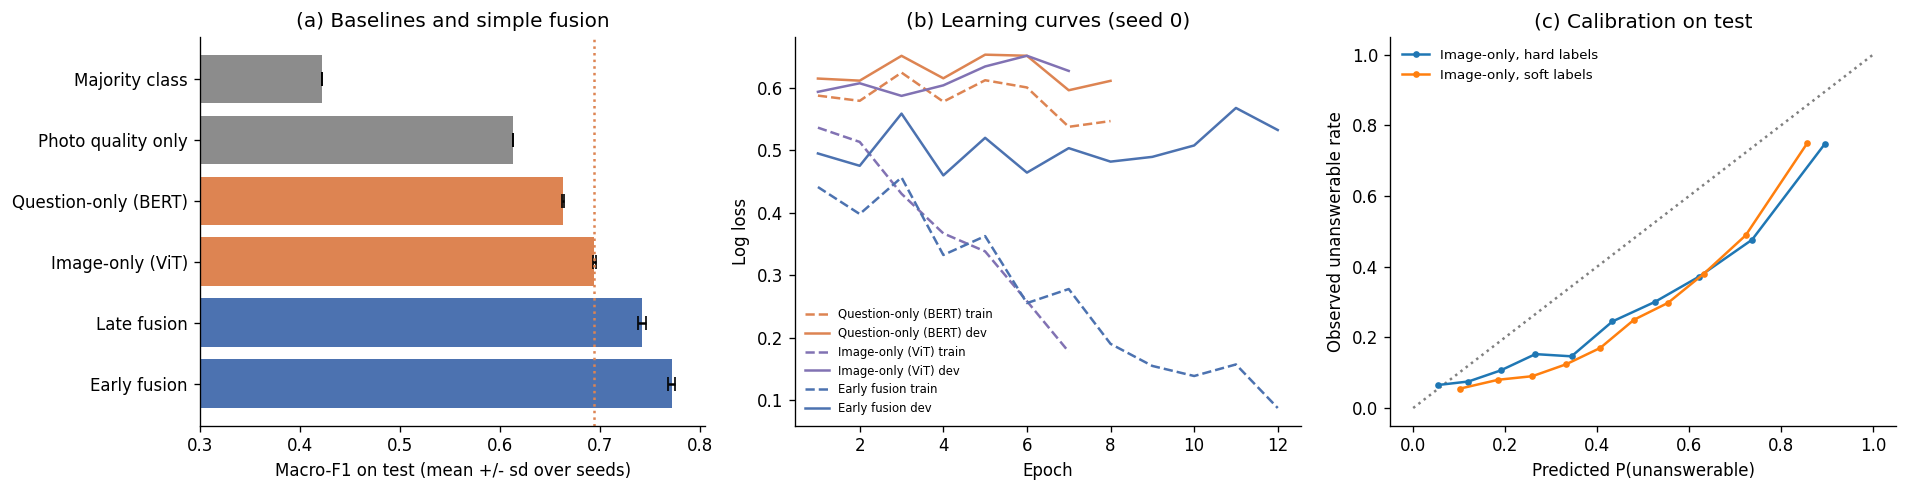

In [18]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

s0 = SEEDS[0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

ax = axes[0]
order = [m for m in MAIN_ORDER if m in MEAN_TEST.index]
mean = MEAN_TEST["macro_f1"].reindex(order)
sd = SC[SC.split == "test"].groupby("model")["macro_f1"].std().reindex(order).fillna(0)
colours = ["#8C8C8C" if m in ("majority", "photo_quality") else "#DD8452" if m in UNIMODAL else "#4C72B0"
           for m in order]
ax.barh([NAMES[m] for m in order], mean, xerr=sd, capsize=4, color=colours)
ax.axvline(MEAN_TEST.loc[BEST_UNI, "macro_f1"], ls=":", color="#DD8452")
ax.invert_yaxis()
ax.set(xlabel="Macro-F1 on test (mean +/- sd over seeds)", title="(a) Baselines and simple fusion",
       xlim=(0.3, min(1.0, float((mean + sd).max()) + 0.03)))

ax = axes[1]
for m, c in zip(["question_only", "image_only", "early"], ("#DD8452", "#8172B3", "#4C72B0")):
    f = RUNS_DIR / m / f"seed{s0}" / "history.csv"
    if f.exists():
        h = pd.read_csv(f)
        ax.plot(h.epoch, h.train_loss, "--", color=c, label=f"{NAMES[m]} train")
        ax.plot(h.epoch, h.dev_loss, "-", color=c, label=f"{NAMES[m]} dev")
ax.set(xlabel="Epoch", ylabel="Log loss", title=f"(b) Learning curves (seed {s0})")
ax.legend(frameon=False, fontsize=7)

ax = axes[2]
ax.plot([0, 1], [0, 1], ":", color="grey")
for key, label in ((("image_only", s0), "Image-only, hard labels"), (("image_only (soft)", s0), "Image-only, soft labels")):
    P = PRED.get(key) or (PRED_SOFT.get(key) if CONFIG["soft_label_ablation"] else None)
    if P is not None:
        frac, conf = calibration_curve(P["test"].y, P["test"].p_unanswerable, n_bins=10, strategy="quantile")
        ax.plot(conf, frac, marker="o", ms=3, label=label)
ax.set(xlabel="Predicted P(unanswerable)", ylabel="Observed unanswerable rate", title="(c) Calibration on test")
ax.legend(frameon=False, fontsize=8)

fig.tight_layout()
fig.savefig(FIG_DIR / "baselines.png", bbox_inches="tight")
plt.show()

## 9. Summary and hand-off

Writes `results/baselines_summary.json` (all numbers for the report) and `HANDOFF.md`.

In [19]:
def to_py(o):
    return o.item() if hasattr(o, "item") else str(o)


if DOWNLOAD_LOG.exists():
    FEAS["downloads"] = json.loads(DOWNLOAD_LOG.read_text())
SUMMARY = {
    "repo_commit": COMMIT, "config": CONFIG, "has_test_labels": HAS_TEST_LABELS, "data": STATS,
    "results_test": MEAN_TEST.round(4).reset_index().to_dict(orient="records"),
    "results_dev": MEAN_DEV.round(4).reset_index().to_dict(orient="records"),
    "best_unimodal": BEST_UNI, "fusion_gain_vs_best_unimodal_test": GAINS, "complementarity_test": COMPLEMENT,
    "ablation_soft_labels_test": ABL.to_dict(orient="records"), "feasibility": FEAS,
}
(RES_DIR / "baselines_summary.json").write_text(json.dumps(SUMMARY, indent=2, default=to_py))

r = STATS["unanswerable_rate_by_split"]
lat = FEAS.get("encoder_latency", {})
print("=== Numbers for the report ===")
print(f"Data: train {len(IDX['train']):,} / dev {len(IDX['dev']):,} / test {len(IDX['test']):,} pairs; "
      f"unanswerable " + ", ".join(f"{k} {v:.1%}" for k, v in r.items()) + ".")
print(f"Label ambiguity: {STATS['ambiguous_answerable_share_train']:.1%} of train pairs are labelled answerable "
      f"with >= 3/10 'unanswerable' votes.")
print(f"Questions: {STATS['duplicate_questions_share_pilot_def']:.1%} of train + dev pairs repeat another pair's "
      f"exact question (proposal: 57.6%); {STATS['rare_question_share_by_split'].get('test', float('nan')):.1%} "
      f"of test questions are rare in train.")
print(f"Photos: unanswerable rate blurry/medium/sharp (train) = {STATS['unanswerable_rate_by_sharp_bin_train']}; "
      f"Mann-Whitney p = {STATS['sharpness_mannwhitney_p_train']:.1e}; unreadable photos {STATS['unreadable_photos']}.")
print(f"Text: {FEAS.get('text_extraction', {}).get('truncated_share', float('nan')):.2%} of questions cut at "
      f"{CONFIG['max_q_tokens']} tokens.")
for m in [m for m in MAIN_ORDER if m in MEAN_TEST.index]:
    e = MEAN_TEST.loc[m]
    extra = f" ({GAINS[m]:+.3f} vs best single)" if m in GAINS else ""
    print(f"{NAMES[m]}: test macro-F1 {e.macro_f1:.3f}{extra}, AUROC {e.auroc:.3f}, AUPRC {e.auprc:.3f}.")
print(f"Best single-modality model (picked on dev): {NAMES[BEST_UNI]}.")
if COMPLEMENT:
    print(f"Complementarity: exactly one modality right on {COMPLEMENT['exactly_one_correct']:.1%} of test pairs; "
          f"oracle accuracy {COMPLEMENT['oracle_accuracy']:.1%}.")
for _, row in ABL[ABL.metric.isin(["macro_f1", "ece"])].iterrows():
    print(f"Soft vs hard, {row['model']}, {row['metric']}: {row['soft - hard']:+.4f}")
print(f"Compute: features on disk {FEAS.get('features_on_disk_gb')} GB; encoders {lat.get('median_ms')} ms median "
      f"per query (p95 {lat.get('p95_ms')} ms) on {lat.get('device')}.")

=== Numbers for the report ===
Data: train 20,523 / dev 4,319 / test 8,000 pairs; unanswerable dev 32.1%, test 26.8%, train 27.0%.
Label ambiguity: 12.2% of train pairs are labelled answerable with >= 3/10 'unanswerable' votes.
Questions: 57.6% of train + dev pairs repeat another pair's exact question (proposal: 57.6%); 46.2% of test questions are rare in train.
Photos: unanswerable rate blurry/medium/sharp (train) = {'blurry': 0.402, 'medium': 0.231, 'sharp': 0.176}; Mann-Whitney p = 1.1e-244; unreadable photos 0.
Text: 0.91% of questions cut at 40 tokens.
Majority class: test macro-F1 0.423, AUROC 0.500, AUPRC 0.268.
Photo quality only: test macro-F1 0.613, AUROC 0.660, AUPRC 0.453.
Question-only (BERT): test macro-F1 0.663, AUROC 0.748, AUPRC 0.536.
Image-only (ViT): test macro-F1 0.694, AUROC 0.778, AUPRC 0.597.
Late fusion: test macro-F1 0.742 (+0.048 vs best single), AUROC 0.842, AUPRC 0.674.
Early fusion: test macro-F1 0.771 (+0.077 vs best single), AUROC 0.871, AUPRC 0.733.
Bes

In [20]:
HANDOFF = f'''# Hand-off from data and baselines (Sanjai)

Generated {time.strftime("%Y-%m-%d %H:%M")} with repo commit `{COMMIT}`. Feature fingerprint `{FINGERPRINT}`.
Rows: train {len(IDX["train"]):,} / dev {len(IDX["dev"]):,} / test {len(IDX["test"]):,} (test labels from {TEST_LABELS.name}).

## Features (read by src/data.py)
- `features/manifest.json`: every feature array, its file, shape and encoder.
- `features/meta.csv`: one row per pair in feature order. Contract columns: pair_id, question, official_split,
  y, unans_votes. Subgroup columns for the bias part: sharp_bin (blurry/medium/sharp), rare_question,
  q_freq_train, answer_type, sharpness, brightness. Contains questions: never commit it to GitHub.
- `features/<name>_{FINGERPRINT}.npy`: {", ".join(feature_names)}

## Runs (docs/data_contract.md format)
- `runs/<model>/seed<k>/predictions.csv` for: {", ".join(sorted(m for m in MEAN_TEST.index))}.
- `runs_ablation_soft/`: question_only and image_only trained with data.label = soft.
- Configs used: `results/train_config_hard.yaml`, `results/train_config_soft.yaml`.

## Rules
- Train on train, tune and select on dev, use test only for final numbers.
- Never use answers, answer_type, vote_share or unans_votes as model inputs (they leak the label).

## The bar to beat (test, mean over seeds)
Best single-modality model (picked on dev): {NAMES[BEST_UNI]}, macro-F1 {MEAN_TEST.loc[BEST_UNI, "macro_f1"]:.3f}.
''' + "\n".join(f"- {NAMES[m]}: macro-F1 {MEAN_TEST.loc[m, 'macro_f1']:.3f}, AUPRC {MEAN_TEST.loc[m, 'auprc']:.3f}"
                for m in FUSION) + "\n"
(OUT / "HANDOFF.md").write_text(HANDOFF)
print(HANDOFF)

# Hand-off from data and baselines (Sanjai)

Generated 2026-10-26 12:32 with repo commit `6e20a67`. Feature fingerprint `895f3ed603bb`.
Rows: train 20,523 / dev 4,319 / test 8,000 (test labels from VQA_test.json).

## Features (read by src/data.py)
- `features/manifest.json`: every feature array, its file, shape and encoder.
- `features/meta.csv`: one row per pair in feature order. Contract columns: pair_id, question, official_split,
  y, unans_votes. Subgroup columns for the bias part: sharp_bin (blurry/medium/sharp), rare_question,
  q_freq_train, answer_type, sharpness, brightness. Contains questions: never commit it to GitHub.
- `features/<name>_895f3ed603bb.npy`: img_cls, img_tok, img_ok, txt_cls, txt_mean, txt_tok, txt_mask, clip_img, clip_txt

## Runs (docs/data_contract.md format)
- `runs/<model>/seed<k>/predictions.csv` for: early, image_only, late, majority, photo_quality, question_only.
- `runs_ablation_soft/`: question_only and image_only trained with data.label = soft.
- C

## 10. Save a clean copy for GitHub

Colab adds widget data to notebooks, which GitHub cannot display. After **Run all** has finished, this cell saves a clean copy of this notebook (outputs kept, widget data removed) to `notebook_for_github/` on Drive. Download that file and upload it to the repo.

In [21]:
def clean_notebook(nb):
    nb.get("metadata", {}).pop("widgets", None)
    for cell in nb.get("cells", []):
        outs = []
        for o in cell.get("outputs", []):
            data = o.get("data")
            if data is not None:
                data.pop("application/vnd.jupyter.widget-view+json", None)
                if not data:
                    continue
            outs.append(o)
        if "outputs" in cell:
            cell["outputs"] = outs
    return nb


try:
    from google.colab import _message
    nb = _message.blocking_request("get_ipynb", request="", timeout_sec=120)["ipynb"]
    dest = OUT / "notebook_for_github" / "02_data_and_baselines.ipynb"
    dest.parent.mkdir(exist_ok=True)
    dest.write_text(json.dumps(clean_notebook(nb), indent=1, ensure_ascii=True))
    print("Clean copy saved to", dest)
except Exception as e:
    print("Not in Colab (or the notebook could not be read), so no clean copy was saved:", type(e).__name__)

Clean copy saved to /content/drive/MyDrive/vizwiz_fusion/notebook_for_github/02_data_and_baselines.ipynb


## References

Devlin, J, Chang, M-W, Lee, K & Toutanova, K 2019, 'BERT: pre-training of deep bidirectional transformers for language understanding', in *Proceedings of the 2019 conference of the North American chapter of the Association for Computational Linguistics: human language technologies*, vol. 1, Association for Computational Linguistics, Minneapolis, USA, pp. 4171-4186.

Dosovitskiy, A, Beyer, L, Kolesnikov, A, Weissenborn, D, Zhai, X, Unterthiner, T, Dehghani, M, Minderer, M, Heigold, G, Gelly, S, Uszkoreit, J & Houlsby, N 2021, 'An image is worth 16x16 words: transformers for image recognition at scale', in *International conference on learning representations (ICLR 2021)*, online.

Gurari, D, Li, Q, Stangl, AJ, Guo, A, Lin, C, Grauman, K, Luo, J & Bigham, JP 2018, 'VizWiz grand challenge: answering visual questions from blind people', in *Proceedings of the IEEE conference on computer vision and pattern recognition (CVPR)*, IEEE, Salt Lake City, USA, pp. 3608-3617.

Mann, HB & Whitney, DR 1947, 'On a test of whether one of two random variables is stochastically larger than the other', *Annals of Mathematical Statistics*, vol. 18, no. 1, pp. 50-60.

Pech-Pacheco, JL, Cristobal, G, Chamorro-Martinez, J & Fernandez-Valdivia, J 2000, 'Diatom autofocusing in brightfield microscopy: a comparative study', in *Proceedings of the 15th international conference on pattern recognition (ICPR 2000)*, vol. 3, IEEE, Barcelona, Spain, pp. 314-317.

Radford, A, Kim, JW, Hallacy, C, Ramesh, A, Goh, G, Agarwal, S, Sastry, G, Askell, A, Mishkin, P, Clark, J, Krueger, G & Sutskever, I 2021, 'Learning transferable visual models from natural language supervision', in *Proceedings of the 38th international conference on machine learning (ICML 2021)*, PMLR, vol. 139, pp. 8748-8763.

VizWiz n.d., *Visual question answering*, VizWiz, viewed 26 October 2026, <https://vizwiz.org/tasks-and-datasets/vqa/>.